# Smartphone Usage Analysis: Exploring Digital Habits, Lifestyle and Smartphone Addiction

## 1. Introduction

## 2. Data Collection

In [2]:
%pip -q install kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os
import glob

sns.set_theme(style="whitegrid")

In [4]:
path = kagglehub.dataset_download(
    "khushikyad001/global-mobile-phone-addiction-dataset"
)

print(path)

C:\Users\Chris Maria Shajan C\.cache\kagglehub\datasets\khushikyad001\global-mobile-phone-addiction-dataset\versions\1


In [5]:
csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

print(csv_files)

['C:\\Users\\Chris Maria Shajan C\\.cache\\kagglehub\\datasets\\khushikyad001\\global-mobile-phone-addiction-dataset\\versions\\1\\mobile_addiction_data.csv']


In [6]:
df = pd.read_csv(csv_files[0])

df.head()

,User_ID,Country,Age,Gender,Occupation,Education_Level,Income_USD,Daily_Screen_Time_Hours,Phone_Unlocks_Per_Day,Social_Media_Usage_Hours,...,Online_Shopping_Hours,Internet_Connection_Type,Primary_Device_Brand,Has_Screen_Time_Management_App,Self_Reported_Addiction_Level,Monthly_Data_Usage_GB,Has_Night_Mode_On,Age_First_Phone,Push_Notifications_Per_Day,Tech_Savviness_Score
0,1,India,32,Male,Salesperson,High School,43865.49,5.81,75,0.84,...,1.85,5G,Other,No,Low,16.43,Yes,16,106,39.36
1,2,UK,26,Male,Artist,Master's,41868.19,9.05,61,3.13,...,0.66,4G,Samsung,Yes,Severe,32.87,No,12,111,9.45
2,3,Germany,70,Other,Doctor,High School,59636.51,5.76,58,2.12,...,-0.14,WiFi,Samsung,Yes,Severe,27.45,No,18,90,50.27
3,4,UK,44,Female,Engineer,NaN,39022.07,6.71,80,1.60,...,0.17,3G,Apple,Yes,Moderate,30.85,No,17,60,30.82
4,5,Brazil,46,Other,Student,NaN,-783.98,6.31,136,1.51,...,0.58,3G,Xiaomi,No,High,10.38,Yes,18,127,21.70


## 3. Data Understanding

In [7]:
df.shape

(3000, 34)

In [8]:
df.columns.tolist()

['User_ID',
 'Country',
 'Age',
 'Gender',
 'Occupation',
 'Education_Level',
 'Income_USD',
 'Daily_Screen_Time_Hours',
 'Phone_Unlocks_Per_Day',
 'Social_Media_Usage_Hours',
 'Gaming_Usage_Hours',
 'Streaming_Usage_Hours',
 'Messaging_Usage_Hours',
 'Work_Related_Usage_Hours',
 'Sleep_Hours',
 'Physical_Activity_Hours',
 'Mental_Health_Score',
 'Depression_Score',
 'Anxiety_Score',
 'Stress_Level',
 'Relationship_Status',
 'Has_Children',
 'Urban_or_Rural',
 'Time_Spent_With_Family_Hours',
 'Online_Shopping_Hours',
 'Internet_Connection_Type',
 'Primary_Device_Brand',
 'Has_Screen_Time_Management_App',
 'Self_Reported_Addiction_Level',
 'Monthly_Data_Usage_GB',
 'Has_Night_Mode_On',
 'Age_First_Phone',
 'Push_Notifications_Per_Day',
 'Tech_Savviness_Score']

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 34 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   User_ID                         3000 non-null   int64  
 1   Country                         3000 non-null   str    
 2   Age                             3000 non-null   int64  
 3   Gender                          3000 non-null   str    
 4   Occupation                      3000 non-null   str    
 5   Education_Level                 2388 non-null   str    
 6   Income_USD                      3000 non-null   float64
 7   Daily_Screen_Time_Hours         3000 non-null   float64
 8   Phone_Unlocks_Per_Day           3000 non-null   int64  
 9   Social_Media_Usage_Hours        3000 non-null   float64
 10  Gaming_Usage_Hours              3000 non-null   float64
 11  Streaming_Usage_Hours           3000 non-null   float64
 12  Messaging_Usage_Hours           3000 non-null

In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
User_ID,3000.0,NaN,NaN,NaN,1500.5,866.169729,1.0,750.75,1500.5,2250.25,3000.0
Country,3000,10,Japan,317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,3000.0,NaN,NaN,NaN,41.307333,17.052345,12.0,27.0,42.0,56.0,70.0
Gender,3000,3,Male,1047,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,3000,8,Unemployed,392,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Education_Level,2388,4,High School,621,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Income_USD,3000.0,NaN,NaN,NaN,29779.511047,15377.473743,-25622.66,19482.705,30002.71,40352.0175,79829.55
Daily_Screen_Time_Hours,3000.0,NaN,NaN,NaN,5.984397,2.018142,-0.5,4.5975,5.98,7.3025,12.87
Phone_Unlocks_Per_Day,3000.0,NaN,NaN,NaN,79.699667,25.155683,-7.0,63.0,80.0,96.0,182.0
Social_Media_Usage_Hours,3000.0,NaN,NaN,NaN,1.988487,0.983224,-1.81,1.34,2.01,2.64,5.05


In [11]:
df.isnull().sum()

User_ID                             0
Country                             0
Age                                 0
Gender                              0
Occupation                          0
Education_Level                   612
Income_USD                          0
Daily_Screen_Time_Hours             0
Phone_Unlocks_Per_Day               0
Social_Media_Usage_Hours            0
Gaming_Usage_Hours                  0
Streaming_Usage_Hours               0
Messaging_Usage_Hours               0
Work_Related_Usage_Hours            0
Sleep_Hours                         0
Physical_Activity_Hours             0
Mental_Health_Score                 0
Depression_Score                    0
Anxiety_Score                       0
Stress_Level                        0
Relationship_Status                 0
Has_Children                        0
Urban_or_Rural                      0
Time_Spent_With_Family_Hours        0
Online_Shopping_Hours               0
Internet_Connection_Type            0
Primary_Devi

In [12]:
df.duplicated().sum()

np.int64(0)

## 4. Data Preprocessing

In [13]:
numeric_cols = df.select_dtypes(include="number").columns

(df[numeric_cols] < 0).sum()

User_ID                           0
Age                               0
Income_USD                       81
Daily_Screen_Time_Hours           9
Phone_Unlocks_Per_Day             1
Social_Media_Usage_Hours         70
Gaming_Usage_Hours              213
Streaming_Usage_Hours            67
Messaging_Usage_Hours             2
Work_Related_Usage_Hours         53
Sleep_Hours                       0
Physical_Activity_Hours          80
Mental_Health_Score               0
Depression_Score                  0
Anxiety_Score                     0
Stress_Level                      0
Time_Spent_With_Family_Hours     96
Online_Shopping_Hours           181
Monthly_Data_Usage_GB            16
Age_First_Phone                   0
Push_Notifications_Per_Day        3
Tech_Savviness_Score              0
dtype: int64

In [14]:
df[
    [
        "Age",
        "Daily_Screen_Time_Hours",
        "Sleep_Hours",
        "Physical_Activity_Hours",
        "Social_Media_Usage_Hours",
        "Gaming_Usage_Hours",
        "Streaming_Usage_Hours",
        "Messaging_Usage_Hours",
        "Work_Related_Usage_Hours",
        "Time_Spent_With_Family_Hours",
        "Online_Shopping_Hours",
        "Income_USD",
        "Monthly_Data_Usage_GB",
        "Phone_Unlocks_Per_Day",
        "Push_Notifications_Per_Day"
    ]
].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,3000.0,41.307333,17.052345,12.00,27.0000,42.000,56.0000,70.00
Daily_Screen_Time_Hours,3000.0,5.984397,2.018142,-0.50,4.5975,5.980,7.3025,12.87
Sleep_Hours,3000.0,6.492713,0.993489,2.81,5.8400,6.480,7.1600,10.32
Physical_Activity_Hours,3000.0,0.996127,0.499560,-0.84,0.6500,1.010,1.3300,2.80
Social_Media_Usage_Hours,3000.0,1.988487,0.983224,-1.81,1.3400,2.010,2.6400,5.05
Gaming_Usage_Hours,3000.0,1.486617,0.997255,-1.93,0.8100,1.510,2.1800,4.86
Streaming_Usage_Hours,3000.0,1.981433,1.004578,-1.91,1.2900,2.010,2.6500,5.18
Messaging_Usage_Hours,3000.0,1.489170,0.508830,-0.18,1.1400,1.500,1.8400,3.07
Work_Related_Usage_Hours,3000.0,1.995423,0.972245,-1.16,1.3400,1.980,2.6700,5.26
Time_Spent_With_Family_Hours,3000.0,1.451450,0.803806,-1.61,0.9200,1.450,1.9900,4.52


In [15]:
df["Education_Level"] = df["Education_Level"].fillna("Unknown")

df["Education_Level"].isnull().sum()

np.int64(0)

In [16]:
non_negative_cols = [
    "Daily_Screen_Time_Hours",
    "Phone_Unlocks_Per_Day",
    "Social_Media_Usage_Hours",
    "Gaming_Usage_Hours",
    "Streaming_Usage_Hours",
    "Messaging_Usage_Hours",
    "Work_Related_Usage_Hours",
    "Sleep_Hours",
    "Physical_Activity_Hours",
    "Time_Spent_With_Family_Hours",
    "Online_Shopping_Hours",
    "Monthly_Data_Usage_GB",
    "Push_Notifications_Per_Day"
]

for col in non_negative_cols:
    df.loc[df[col] < 0, col] = np.nan
    df[col] = df[col].fillna(df[col].median())

df[non_negative_cols].isnull().sum()

Daily_Screen_Time_Hours         0
Phone_Unlocks_Per_Day           0
Social_Media_Usage_Hours        0
Gaming_Usage_Hours              0
Streaming_Usage_Hours           0
Messaging_Usage_Hours           0
Work_Related_Usage_Hours        0
Sleep_Hours                     0
Physical_Activity_Hours         0
Time_Spent_With_Family_Hours    0
Online_Shopping_Hours           0
Monthly_Data_Usage_GB           0
Push_Notifications_Per_Day      0
dtype: int64

In [17]:
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate records:", df.duplicated().sum())

display(df.head())

Dataset shape: (3000, 34)
Missing values: 0
Duplicate records: 0


,User_ID,Country,Age,Gender,Occupation,Education_Level,Income_USD,Daily_Screen_Time_Hours,Phone_Unlocks_Per_Day,Social_Media_Usage_Hours,...,Online_Shopping_Hours,Internet_Connection_Type,Primary_Device_Brand,Has_Screen_Time_Management_App,Self_Reported_Addiction_Level,Monthly_Data_Usage_GB,Has_Night_Mode_On,Age_First_Phone,Push_Notifications_Per_Day,Tech_Savviness_Score
0,1,India,32,Male,Salesperson,High School,43865.49,5.81,75.0,0.84,...,1.85,5G,Other,No,Low,16.43,Yes,16,106.0,39.36
1,2,UK,26,Male,Artist,Master's,41868.19,9.05,61.0,3.13,...,0.66,4G,Samsung,Yes,Severe,32.87,No,12,111.0,9.45
2,3,Germany,70,Other,Doctor,High School,59636.51,5.76,58.0,2.12,...,0.83,WiFi,Samsung,Yes,Severe,27.45,No,18,90.0,50.27
3,4,UK,44,Female,Engineer,Unknown,39022.07,6.71,80.0,1.60,...,0.17,3G,Apple,Yes,Moderate,30.85,No,17,60.0,30.82
4,5,Brazil,46,Other,Student,Unknown,-783.98,6.31,136.0,1.51,...,0.58,3G,Xiaomi,No,High,10.38,Yes,18,127.0,21.70


## 5. Exploratory Data Analysis (EDA)

### 5.1 Distribution of Smartphone Usage

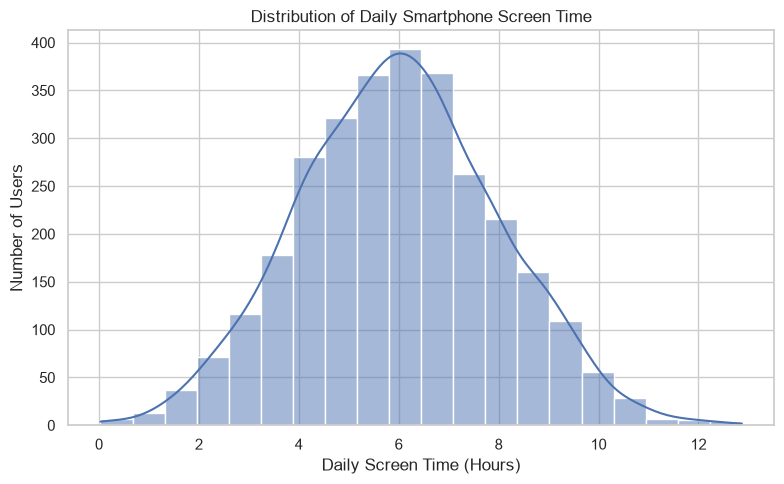

In [18]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="Daily_Screen_Time_Hours",
    bins=20,
    kde=True
)

plt.title("Distribution of Daily Smartphone Screen Time")
plt.xlabel("Daily Screen Time (Hours)")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

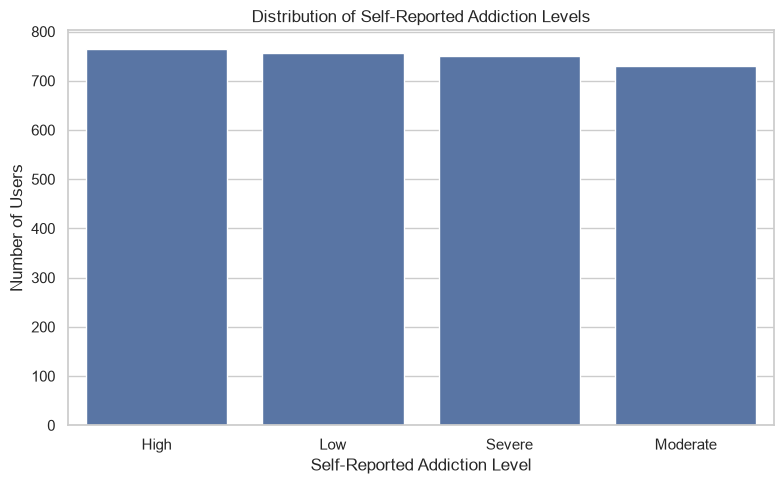

In [19]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Self_Reported_Addiction_Level",
    order=df["Self_Reported_Addiction_Level"].value_counts().index
)

plt.title("Distribution of Self-Reported Addiction Levels")
plt.xlabel("Self-Reported Addiction Level")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

### 5.2 Smartphone Usage and Sleep Analysis

In [20]:
df[["Daily_Screen_Time_Hours", "Sleep_Hours"]].mean()

Daily_Screen_Time_Hours    6.003090
Sleep_Hours                6.492713
dtype: float64

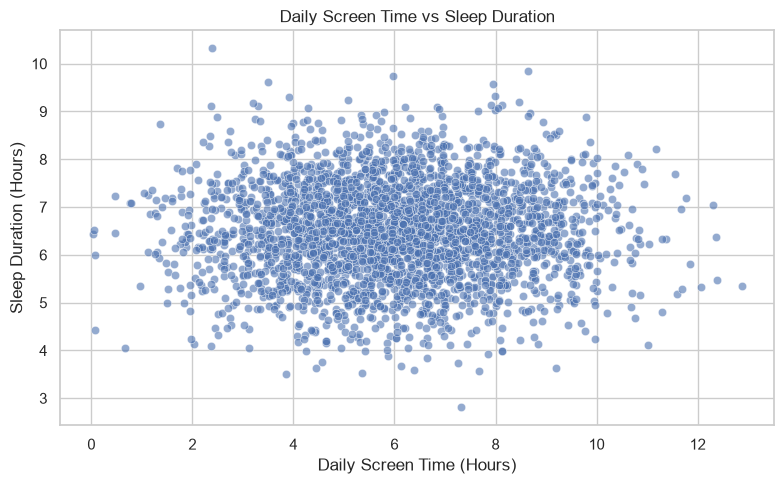

In [21]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Daily_Screen_Time_Hours",
    y="Sleep_Hours",
    alpha=0.6
)

plt.title("Daily Screen Time vs Sleep Duration")
plt.xlabel("Daily Screen Time (Hours)")
plt.ylabel("Sleep Duration (Hours)")
plt.tight_layout()
plt.show()

In [22]:
df["Daily_Screen_Time_Hours"].corr(df["Sleep_Hours"])

np.float64(0.007457458840391849)

### 5.3 Usage Patterns Across Addiction Levels

In [23]:
addiction_order = ["Low", "Moderate", "High", "Severe"]

df.groupby(
    "Self_Reported_Addiction_Level",
    observed=True
)["Daily_Screen_Time_Hours"].mean().reindex(addiction_order)

Self_Reported_Addiction_Level
Low         6.095079
Moderate    5.932466
High        5.993115
Severe      5.989267
Name: Daily_Screen_Time_Hours, dtype: float64

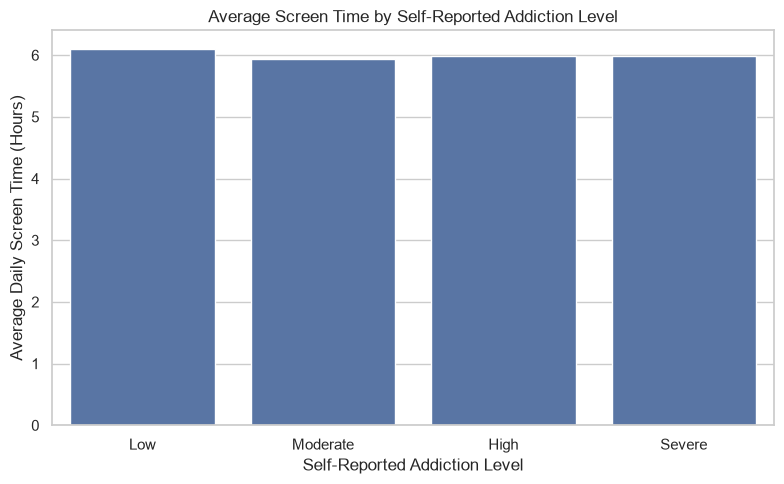

In [24]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Self_Reported_Addiction_Level",
    y="Daily_Screen_Time_Hours",
    order=addiction_order,
    errorbar=None
)

plt.title("Average Screen Time by Self-Reported Addiction Level")
plt.xlabel("Self-Reported Addiction Level")
plt.ylabel("Average Daily Screen Time (Hours)")
plt.tight_layout()
plt.show()

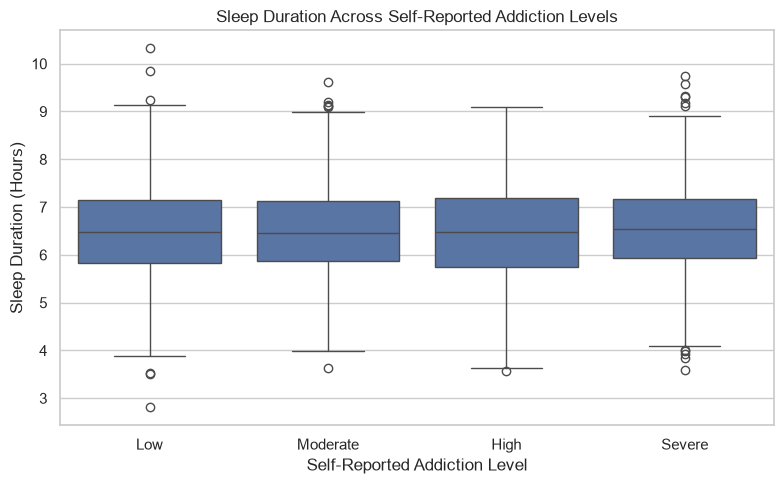

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Self_Reported_Addiction_Level",
    y="Sleep_Hours",
    order=addiction_order
)

plt.title("Sleep Duration Across Self-Reported Addiction Levels")
plt.xlabel("Self-Reported Addiction Level")
plt.ylabel("Sleep Duration (Hours)")
plt.tight_layout()
plt.show()

### 5.4 Smartphone Usage and Mental Well-being Indicators

In [26]:
df[
    [
        "Daily_Screen_Time_Hours",
        "Sleep_Hours",
        "Mental_Health_Score",
        "Depression_Score",
        "Anxiety_Score",
        "Stress_Level",
        "Physical_Activity_Hours"
    ]
].corr()

,Daily_Screen_Time_Hours,Sleep_Hours,Mental_Health_Score,Depression_Score,Anxiety_Score,Stress_Level,Physical_Activity_Hours
Daily_Screen_Time_Hours,1.000000,0.007457,-0.033739,-0.030611,-0.007430,0.016547,0.012352
Sleep_Hours,0.007457,1.000000,0.011360,0.051406,-0.009249,0.002822,-0.000581
Mental_Health_Score,-0.033739,0.011360,1.000000,0.018604,-0.012941,0.007978,0.023512
Depression_Score,-0.030611,0.051406,0.018604,1.000000,-0.009039,-0.004368,0.016297
Anxiety_Score,-0.007430,-0.009249,-0.012941,-0.009039,1.000000,0.043730,0.010193
Stress_Level,0.016547,0.002822,0.007978,-0.004368,0.043730,1.000000,-0.002713
Physical_Activity_Hours,0.012352,-0.000581,0.023512,0.016297,0.010193,-0.002713,1.000000


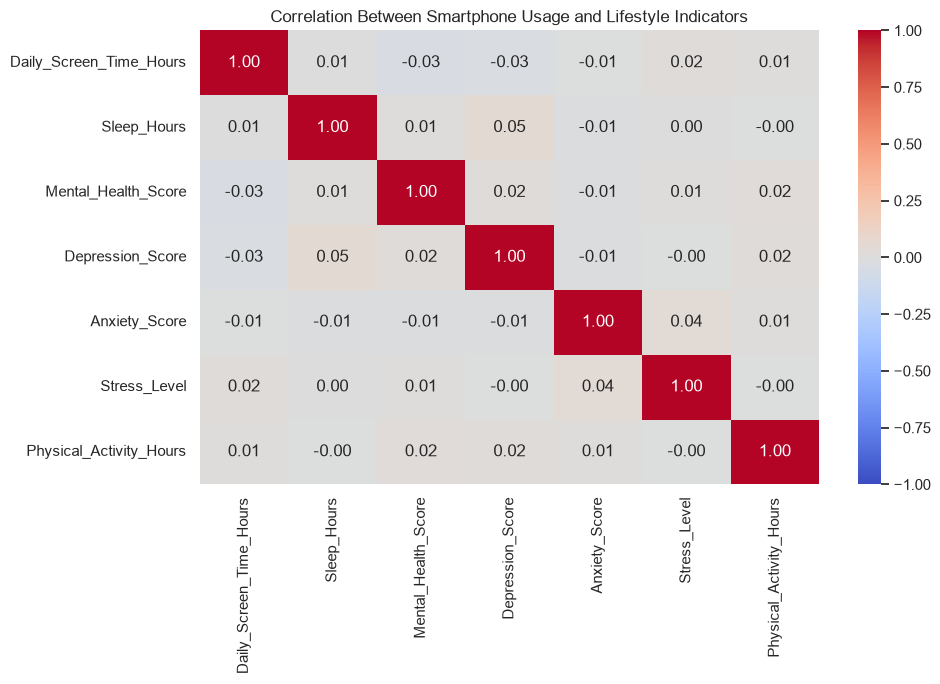

In [27]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    df[
        [
            "Daily_Screen_Time_Hours",
            "Sleep_Hours",
            "Mental_Health_Score",
            "Depression_Score",
            "Anxiety_Score",
            "Stress_Level",
            "Physical_Activity_Hours"
        ]
    ].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Smartphone Usage and Lifestyle Indicators")
plt.tight_layout()
plt.show()

## 6. Statistical Analysis

In [28]:
df.groupby("Self_Reported_Addiction_Level")[
    [
        "Daily_Screen_Time_Hours",
        "Sleep_Hours",
        "Phone_Unlocks_Per_Day",
        "Stress_Level"
    ]
].agg(["mean", "median", "std"]).round(2)

Daily_Screen_Time_Hours               \
                                                 mean median   std   
Self_Reported_Addiction_Level                                        
High                                             5.99   6.00  2.02   
Low                                              6.10   6.08  2.01   
Moderate                                         5.93   5.94  1.97   
Severe                                           5.99   5.96  1.95   

                              Sleep_Hours              Phone_Unlocks_Per_Day  \
                                     mean median   std                  mean   
Self_Reported_Addiction_Level                                                  
High                                 6.47   6.47  1.02                 78.76   
Low                                  6.49   6.48  0.99                 80.48   
Moderate                             6.49   6.45  0.94                 78.44   
Severe                               6.52   6.55  1.02                 81.22   

                                            Stress_Level                
                              median    std         mean median    std  
Self_Reported_Addiction_Level                                           
High                            80.0  25.18        48.88  46.92  28.80  
Low                             80.0  24.89        49.45  48.84  28.11  
Moderate                        78.0  25.64        48.10  47.90  28.56  
Severe                          82.0  24.67        51.07  51.54  28.85

In [29]:
from scipy.stats import pearsonr

r, p = pearsonr(
    df["Daily_Screen_Time_Hours"],
    df["Sleep_Hours"]
)

print("Pearson correlation:", round(r, 3))
print("P-value:", round(p, 4))

Pearson correlation: 0.007
P-value: 0.6831


## 7. Feature Engineering

In [30]:
df["Screen_Time_Category"] = pd.cut(
    df["Daily_Screen_Time_Hours"],
    bins=[-np.inf, 4, 7, np.inf],
    labels=["Low", "Moderate", "High"]
)

df[["Daily_Screen_Time_Hours", "Screen_Time_Category"]].head()

,Daily_Screen_Time_Hours,Screen_Time_Category
0,5.81,Moderate
1,9.05,High
2,5.76,Moderate
3,6.71,Moderate
4,6.31,Moderate


In [31]:
recreational_cols = [
    "Social_Media_Usage_Hours",
    "Gaming_Usage_Hours",
    "Streaming_Usage_Hours",
    "Messaging_Usage_Hours",
    "Online_Shopping_Hours"
]

df["Combined_Activity_Hours"] = df[recreational_cols].sum(axis=1)

df[["Combined_Activity_Hours", "Daily_Screen_Time_Hours"]].head()

,Combined_Activity_Hours,Daily_Screen_Time_Hours
0,9.11,5.81
1,9.51,9.05
2,8.73,5.76
3,8.80,6.71
4,6.60,6.31


In [32]:
df["Screen_Time_Category"].value_counts().reindex(
    ["Low", "Moderate", "High"]
)

Screen_Time_Category
Low          473
Moderate    1634
High         893
Name: count, dtype: int64

In [33]:
pd.crosstab(
    df["Screen_Time_Category"],
    df["Self_Reported_Addiction_Level"],
    normalize="index"
).round(3) * 100

Self_Reported_Addiction_Level,High,Low,Moderate,Severe
Screen_Time_Category,,,,
Low,26.8,22.4,24.9,25.8
Moderate,25.2,24.8,24.5,25.5
High,25.3,27.4,23.6,23.6


## 8. Comparative Analysis and Visualization

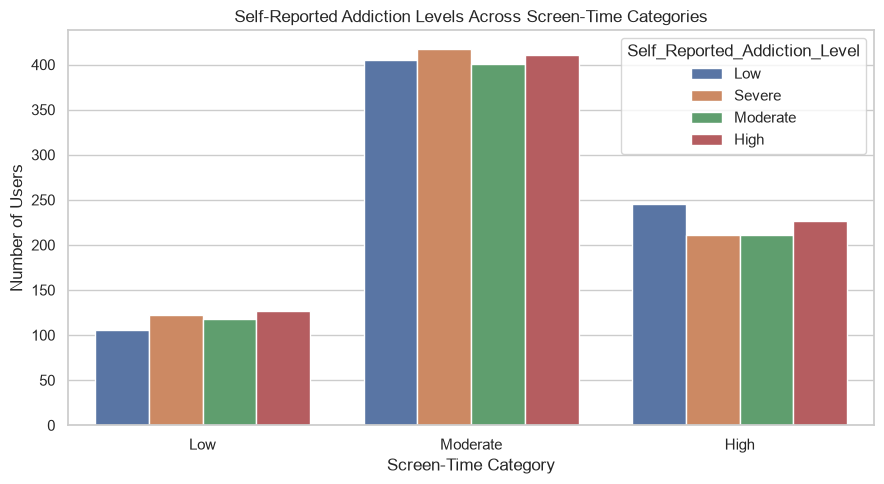

In [34]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Screen_Time_Category",
    hue="Self_Reported_Addiction_Level",
    order=["Low", "Moderate", "High"]
)

plt.title("Self-Reported Addiction Levels Across Screen-Time Categories")
plt.xlabel("Screen-Time Category")
plt.ylabel("Number of Users")
plt.tight_layout()
plt.show()

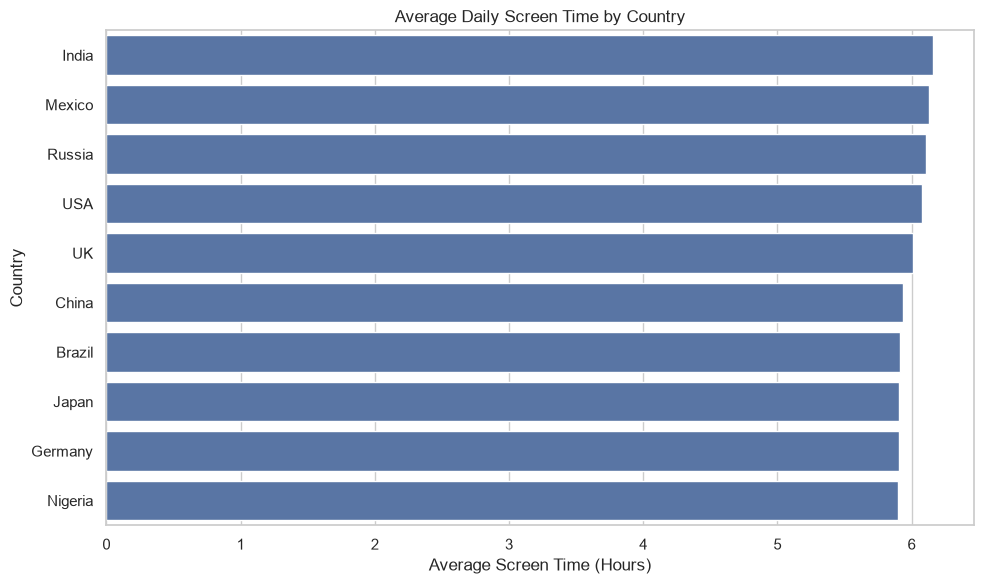

In [35]:
country_usage = (
    df.groupby("Country")["Daily_Screen_Time_Hours"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=country_usage.values,
    y=country_usage.index,
    errorbar=None
)

plt.title("Average Daily Screen Time by Country")
plt.xlabel("Average Screen Time (Hours)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

## 9. Key Findings

In [36]:
print("Total number of users:", len(df))

print("\nAverage daily screen time:",
      round(df["Daily_Screen_Time_Hours"].mean(), 2), "hours")

print("Average sleep duration:",
      round(df["Sleep_Hours"].mean(), 2), "hours")

print("\nScreen-time category counts:")
print(df["Screen_Time_Category"].value_counts())

print("\nSelf-reported addiction-level counts:")
print(df["Self_Reported_Addiction_Level"].value_counts())

print("\nAverage screen time by country:")
print(country_usage.round(2))

Total number of users: 3000

Average daily screen time: 6.0 hours
Average sleep duration: 6.49 hours

Screen-time category counts:
Screen_Time_Category
Moderate    1634
High         893
Low          473
Name: count, dtype: int64

Self-reported addiction-level counts:
Self_Reported_Addiction_Level
High        764
Low         756
Severe      750
Moderate    730
Name: count, dtype: int64

Average screen time by country:
Country
India      6.16
Mexico     6.13
Russia     6.11
USA        6.08
UK         6.01
China      5.94
Brazil     5.91
Japan      5.91
Germany    5.90
Nigeria    5.90
Name: Daily_Screen_Time_Hours, dtype: float64


In [37]:
screen_time_percent = (
    df["Screen_Time_Category"]
    .value_counts(normalize=True)
    .reindex(["Low", "Moderate", "High"])
    .mul(100)
    .round(2)
)

print(screen_time_percent)

Screen_Time_Category
Low         15.77
Moderate    54.47
High        29.77
Name: proportion, dtype: float64


## 10. Sustainable Development Goals (SDG) Alignment

### SDG 3: Good Health and Well-being

This project supports awareness of digital well-being by exploring smartphone usage patterns and their relationships with sleep, physical activity, and self-reported mental well-being indicators.

### SDG 4: Quality Education

The project promotes data literacy and awareness of balanced technology use. However, educational outcomes were not directly measured in this analysis.

## 11. Conclusion

This project analyzed smartphone usage patterns using a dataset containing 3,000 records and 34 variables. Data preprocessing, exploratory data analysis, feature engineering, visualization, and statistical analysis were performed to understand digital habits and their relationships with lifestyle indicators.

The analysis found an almost zero correlation between daily screen time and sleep duration in this dataset. Screen-time categories also showed similar distributions of self-reported addiction levels, indicating that screen time alone may not explain these self-reported categories.

The project demonstrates how data analytics can help explore digital habits and encourage awareness of digital well-being. The findings describe associations within the available dataset and do not establish causation or provide a clinical diagnosis.